In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "061a82116be00c585cab41d5b2a790e2a4f96d44"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/061a82116be00c585cab41d5b2a790e2a4f96d44/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Test Functions and Transport

A model whose samples miss the data learns nothing from an f-divergence. On
disjoint supports every member of that family is a constant
(that section), and a constant has no gradient. The verdict
rested on two point masses, the extreme case. Real distributions have spread:
two Gaussians overlap everywhere, because their tails never reach zero. Does a
little overlap bring the gradient back? The f-divergences left a second
complaint as well. They need the ratio $p/q$, which samples do not supply, so a
critic had to be trained before anything could be measured
(that section). Can two samples be compared with no critic at
all?

We can settle the first question with numbers. Let the data be
$P = \mathcal{N}(0, 1)$ and the model $Q = \mathcal{N}(d, 1)$, the same bell
curve $d$ standard deviations away, with $d$ the model's one parameter. After
the imports, a cell evaluates the five comparisons of
the table on this pair, each with its slope in $d$,
the gradient that the model receives. Its formulas are derived in this section
and the last; for now, read only the output, which we shall call the opening
table.

In [1]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

In [2]:
from scipy import optimize
from scipy.stats import norm

In [3]:
def js(d, x=np.linspace(-12, 20, 6401)):
    """JS divergence of N(0, 1) and N(d, 1) by quadrature on the grid x."""
    log_p, log_q = norm.logpdf(x), norm.logpdf(x, loc=d)
    log_m = np.logaddexp(log_p, log_q) - math.log(2)    # log of the mixture
    terms = np.exp(log_p) * (log_p - log_m) + np.exp(log_q) * (log_q - log_m)
    return terms.sum() * (x[1] - x[0]) / 2

comparisons = {                       # N(0, 1) against N(d, 1), RBF ell = 1
    'KL': lambda d: d ** 2 / 2,
    'JS': js,
    'TV': lambda d: 2 * norm.cdf(d / 2) - 1,
    'MMD^2': lambda d: 2 / math.sqrt(3) * (1 - math.exp(-d ** 2 / 6)),
    'W1': lambda d: d}
h = 1e-3                              # step of the central difference
print('   d' + ''.join(f'{name:>8s} {"slope":>7s}' for name in comparisons))
for d in (0.5, 1.0, 2.0, 4.0, 8.0):
    print(f'{d:4.1f}' + ''.join(
        f'{f(d):8.3f} {(f(d + h) - f(d - h)) / (2 * h):7.1e}'
        for f in comparisons.values()))

   d      KL   slope      JS   slope      TV   slope   MMD^2   slope      W1   slope
 0.5   0.125 5.0e-01   0.030 1.2e-01   0.197 3.9e-01   0.047 1.8e-01   0.500 1.0e+00
 1.0   0.500 1.0e+00   0.111 2.0e-01   0.383 3.5e-01   0.177 3.3e-01   1.000 1.0e+00
 2.0   2.000 2.0e+00   0.337 2.2e-01   0.683 2.4e-01   0.562 4.0e-01   2.000 1.0e+00
 4.0   8.000 4.0e+00   0.633 6.9e-02   0.954 5.4e-02   1.074 1.1e-01   4.000 1.0e+00
 8.0  32.000 8.0e+00   0.693 2.0e-04   1.000 1.3e-04   1.155 7.2e-05   8.000 1.0e+00


At half a standard deviation all five slopes lie between $0.1$ and $1$, and any
of the comparisons would train the model. At $d = 8$ the Jensen--Shannon
divergence reads $0.693$ and total variation $1.000$, the constants $\log 2$
and $1$ of the point masses, and both slopes are near $10^{-4}$. Overlap in the
tails does not help. The KL divergence keeps a slope, $d$ itself, but only
because a Gaussian model has a density at every data point; a model whose
samples lie on a thin surface has none. That leaves the two comparisons that
kept moving for the point masses. $\textrm{MMD}^2$ grows at first and has
stalled by $d = 8$, at $1.155$ with a slope below $10^{-4}$. $W_1$ equals $d$,
with slope $1$ at every distance.

Neither is built from the ratio $p/q$. MMD compares how $P$ and $Q$ *average* a
class of functions; samples can estimate averages, and the class decides how
far the comparison sees. $W_1$ asks how far mass must travel to turn one
distribution into the other, and it turns out to be a comparison of averages
too. Two results stand out. Over a fixed set of features the comparison of
averages has a closed form, with no second network to train. And the cost of
moving mass equals the largest gap in averages over functions of slope at most
one, the theorem behind the Wasserstein GAN of that section.
$P$ is the data and $Q$ the model, as before, and the examples are on the line.

## Integral Probability Metrics and MMD

### Classes of Test Functions

Total variation is a metric, and still it went flat in the opening table. Its
second form shows why, and what to change: total variation is the largest
disagreement between $P$ and $Q$ about the probability of any event $A$
(that section), $\textrm{TV}(P, Q) = \sup_A |P(A) - Q(A)|$.
The probability of an event is the average of its indicator function, so total
variation is a supremum, over a class of functions, of the difference between
two averages. Nothing obliges us to use indicators. For a class $\mathcal{G}$
of *test functions* $g$, the **integral probability metric** (IPM)
[@Muller.1997] is

$$
\textrm{IPM}_{\mathcal{G}}(P, Q)
= \sup_{g \in \mathcal{G}} \,\big( \mathbb{E}_{x \sim P}[g(x)] - \mathbb{E}_{x \sim Q}[g(x)] \big).
$$

The class $\mathcal{G}$ is a panel of auditors, and the IPM reports the largest
gap in averages that any auditor in the panel can find. Our classes contain
$-g$ along with every $g$, so the gap is never negative and is the same in
both directions; whether it vanishes only for $P = Q$, as the word metric
promises, depends on the class. The critic of
that section was an auditor too. In its bound,
$D_f(P\|Q) \geq \mathbb{E}_P[T] - \mathbb{E}_Q[f^*(T)]$ for every function $T$,
the conjugate $f^*$ keeps an unrestricted critic in check. An IPM averages $g$
itself under both distributions, so nothing restrains $g$ except membership in
$\mathcal{G}$, and everything depends on the class.

Three classes matter to us. Functions with $|g| \leq \tfrac{1}{2}$ give total
variation again: an indicator minus $\tfrac12$ is such a function, the constant
cancels in the difference, and $g = \tfrac12\,\textrm{sign}(p - q)$ attains the
supremum. Functions that are linear in a fixed set of features give the
**maximum mean discrepancy** (MMD) [@Gretton.Borgwardt.Rasch.ea.2012],
which we build next. Functions of slope at most one give the Wasserstein
distance of that section.

Why not take the largest class every time? A class has to meet two
requirements, and size works against the first: averages over a sample must
track averages over the distribution. Samples estimate expectations directly,
with no density ratio, but a panel that is too large finds gaps that are not
there. Two samples of $1{,}000$ points from the same continuous distribution
share no point, so the indicator of the first sample has mean $1$ on it and $0$
on the other: the empirical total variation is $1$ whatever the distributions
are. A class must be small or smooth enough to exclude such functions.

The second requirement is that the gap keep growing as the distributions move
apart, and for that the class needs functions that grow. Total variation has
none: its test functions are bounded, so its gap cannot exceed $1$. The
largest disagreement is about the event $\{p > q\}$, which for the two
Gaussians of the opening is the half-line $x < d/2$. Its two probabilities give
$\textrm{TV} = \Phi(d/2) - \Phi(-d/2) = 2\Phi(d/2) - 1$, where $\Phi$ is the
cumulative distribution function (CDF) of the standard normal. This is $0.954$
at $d = 4$ and within $10^{-4}$ of $1$ at $d = 8$. Once an indicator separates
the two bell curves almost perfectly, moving them further apart changes
nothing. Total variation fails both requirements, and we shall hold the next
two classes to them.

### Mean Features and Kernels

We build a better class from the smallest panel up, and try each stage on one
pair: $\mathcal{N}(0, 1)$ against $\mathcal{N}(0, 4)$, which differ in spread
and not in mean. First, take linear test functions $g(x) = w\, x$ with
$|w| \leq 1$. Then
$\mathbb{E}_P g - \mathbb{E}_Q g = w\,(\mathbb{E}_P X - \mathbb{E}_Q X)$, and
the supremum is $|\mathbb{E}_P X - \mathbb{E}_Q X|$: the IPM over linear
functions is the difference of the means. It cannot see a change of spread, and
on our pair it reports $0$.

Second, add a feature. Take the feature vector
$\boldsymbol{\varphi}(x) = (x, x^2)$ and the test functions
$g(x) = \mathbf{w}^\top \boldsymbol{\varphi}(x)$ with $\|\mathbf{w}\| \leq 1$,
and write $\mathbf{m}_P = \mathbb{E}_P[\boldsymbol{\varphi}(x)]$ for the *mean
feature* of $P$. Then
$\mathbb{E}_P g - \mathbb{E}_Q g = \mathbf{w}^\top(\mathbf{m}_P - \mathbf{m}_Q)$,
and by the Cauchy--Schwarz inequality the largest value of a linear function on
the unit ball is the norm of its coefficient vector:

$$
\textrm{MMD}(P, Q) = \sup_{\|\mathbf{w}\| \leq 1} \mathbf{w}^\top(\mathbf{m}_P - \mathbf{m}_Q)
= \|\mathbf{m}_P - \mathbf{m}_Q\|.
$$

MMD is the distance between the mean features, and the supremum has gone. On
our pair the mean features are $(0, 1)$ and $(0, 4)$, so
$\textrm{MMD}^2 = 0^2 + 3^2 = 9$: means and second moments are now both
compared.

Third, we expand the squared norm. A product of two means is the mean of a
product over independent draws, so
$\|\mathbf{m}_P\|^2 = \mathbb{E}\langle\boldsymbol{\varphi}(x), \boldsymbol{\varphi}(x')\rangle$
for independent $x, x'$ from $P$. With independent $y, y'$ from $Q$ as well,
$\|\mathbf{m}_P - \mathbf{m}_Q\|^2 =
\mathbb{E}\langle\boldsymbol{\varphi}(x), \boldsymbol{\varphi}(x')\rangle +
\mathbb{E}\langle\boldsymbol{\varphi}(y), \boldsymbol{\varphi}(y')\rangle -
2\,\mathbb{E}\langle\boldsymbol{\varphi}(x), \boldsymbol{\varphi}(y)\rangle$.
Only inner products of features appear. We call
$k(x, x') = \langle \boldsymbol{\varphi}(x), \boldsymbol{\varphi}(x')\rangle$
the **kernel** and obtain

$$
\textrm{MMD}^2(P, Q)
= \mathbb{E}_{x, x' \sim P}[k(x, x')] + \mathbb{E}_{y, y' \sim Q}[k(y, y')]
- 2\, \mathbb{E}_{x \sim P, y \sim Q}[k(x, y)].
$$

The first two terms measure similarity within each distribution and the third
similarity across the two. If draws from $P$ and $Q$ interleave, the three
terms cancel; if they form separate clumps, the within terms exceed the across
term. The features of the first step have the *linear kernel*
$k(x, x') = x x'$, and those of the second the *quadratic kernel*
$x x' + x^2 x'^2$.

The quadratic kernel still has a blind spot: two distributions with equal
means and equal variances are at distance zero. We could add $x^3$, then
$x^4$, and never finish. The fourth step therefore chooses the kernel directly,
as a measure of similarity, and never writes the features down. The *RBF
kernel* $k(x, x') = e^{-(x - x')^2/(2\ell^2)}$ calls two points similar when
they lie within about a *length scale* $\ell$ of each other. It is an inner
product of features all the same. It factors as
$e^{-x^2/(2\ell^2)}\, e^{-x'^2/(2\ell^2)}\, e^{x x'/\ell^2}$, and the power
series of the last factor writes it as an inner product of infinitely many
features $\varphi_j(x) = x^j e^{-x^2/(2\ell^2)} / (\ell^j \sqrt{j!})$,
$j = 0, 1, 2, \ldots$, damped monomials of every order with weights that
decrease quickly. The panel now has infinitely many auditors, and its verdict
is still three averages. In $\mathbb{R}^n$ the squared difference in the kernel
becomes a squared norm and nothing else changes.

No blind spot is left. With the RBF kernel, $\textrm{MMD}(P, Q) = 0$ only if
$P = Q$ [@Gretton.Borgwardt.Rasch.ea.2012], so this MMD is a metric. A
kernel with this property is called *characteristic*; the linear and quadratic
kernels are not.

For Gaussians the RBF averages can be computed by hand. For
$Z \sim \mathcal{N}(\mu, s^2)$, a Gaussian integral gives

$$
\mathbb{E}\big[e^{-Z^2/(2\ell^2)}\big]
= \Big(1 + \frac{s^2}{\ell^2}\Big)^{-1/2} \exp\!\Big(-\frac{\mu^2}{2(\ell^2 + s^2)}\Big),
$$

and the difference of two independent Gaussians is Gaussian with the variances
added. On our pair at $\ell = 1$ the three differences $x - x'$, $y - y'$ and
$x - y$ have mean zero and variances $2$, $8$ and $5$, so
$\textrm{MMD}^2 = 3^{-1/2} + 9^{-1/2} - 2 \cdot 6^{-1/2} \approx 0.094$. For
the two Gaussians of the opening the same integral gives
$\tfrac{2}{\sqrt{3}}\big(1 - e^{-d^2/6}\big)$, the $\textrm{MMD}^2$ column of
the opening table (Exercise
1a). For the point masses
of the table there is nothing to average, and
the equation gives $1 + 1 - 2k(0, d) = 2 - 2e^{-d^2/2}$, the fourth row
of that table. In both formulas only the cross term depends on $d$, and it is
gone within a few length scales. The gap stops growing, and the second
requirement is not met. An RBF auditor is smooth, and it is nearsighted.

### Estimation from Samples

The first requirement is where a kernel does well. From samples, each
expectation in the equation becomes an average over pairs. The unbiased
estimator [@Gretton.Borgwardt.Rasch.ea.2012] leaves out the pairs of a
point with itself, which would bias the within terms upward. We apply it to
$N = 1{,}000$ draws from $\mathcal{N}(0, 1)$ and as many from
$\mathcal{N}(0, 4)$ under the linear, quadratic and RBF kernels, for which we
have just found $0$, $9$ and $0.094$. With the RBF kernel we also compare the
first sample with a second one from $\mathcal{N}(0, 1)$, where the answer is
$0$, and with one from $\mathcal{N}(0.5, 1)$, where the opening table says
$0.047$. What the mathematics does not supply is the size of the sampling
error.

In [4]:
def mmd2_unbiased(x, y, k):
    """Unbiased MMD^2 between samples x and y for the kernel k(a, b)."""
    kxx = k(x[:, None], x[None, :])
    kyy = k(y[:, None], y[None, :])
    n, m = len(x), len(y)
    return ((kxx.sum() - np.trace(kxx)) / (n * (n - 1))
            + (kyy.sum() - np.trace(kyy)) / (m * (m - 1))
            - 2 * k(x[:, None], y[None, :]).mean())

linear = lambda a, b: a * b                         # features phi(x) = x
quadratic = lambda a, b: a * b + a ** 2 * b ** 2    # features (x, x^2)
rbf = lambda a, b: np.exp(-(a - b) ** 2 / 2)        # RBF kernel, ell = 1

rng = np.random.default_rng()
n = 1000
x_p = rng.standard_normal(n)                # P = N(0, 1)
y_var = 2 * rng.standard_normal(n)          # N(0, 4)
y_same = rng.standard_normal(n)             # N(0, 1) again
y_shift = rng.standard_normal(n) + 0.5      # N(0.5, 1)
for name, y, k, pop in [
        ('linear,    N(0,1) vs N(0,4)', y_var, linear, 0.0),
        ('quadratic, N(0,1) vs N(0,4)', y_var, quadratic, 9.0),
        ('RBF,       N(0,1) vs N(0,4)', y_var, rbf,
         3 ** -0.5 + 9 ** -0.5 - 2 * 6 ** -0.5),
        ('RBF,       N(0,1) vs N(0,1)', y_same, rbf, 0.0),
        ('RBF,       N(0,1) vs N(0.5,1)', y_shift, rbf,
         2 / np.sqrt(3) * (1 - np.exp(-1 / 24)))]:
    print(f'{name:30s} MMD^2 = {mmd2_unbiased(x_p, y, k):+.4f}  '
          f'(population {pop:.4f})')

linear,    N(0,1) vs N(0,4)    MMD^2 = -0.0026  (population 0.0000)
quadratic, N(0,1) vs N(0,4)    MMD^2 = +8.0798  (population 9.0000)
RBF,       N(0,1) vs N(0,4)    MMD^2 = +0.0971  (population 0.0942)
RBF,       N(0,1) vs N(0,1)    MMD^2 = +0.0025  (population 0.0000)


RBF,       N(0,1) vs N(0.5,1)  MMD^2 = +0.0534  (population 0.0471)


The linear kernel reports a value near zero because the means agree. Its
estimate is the squared difference of the two sample means, less an estimate
of the variance of that difference, about $(1 + 4)/1{,}000 = 0.005$. It
therefore cannot fall much below $-0.005$, while about one run in twenty
exceeds $+0.015$. The quadratic kernel reports about $9$, give or take $3$;
its estimate involves fourth powers and is noisy. The RBF kernel reports about
$0.094$, give or take $0.03$, and for the shifted pair about $0.047$, typically
within $0.02$, an error that can reach a third of the value. Between the two
samples of $\mathcal{N}(0, 1)$ the RBF estimate is far steadier, within a few
thousandths of zero and sometimes below it, because the errors of the three
averages then cancel to first order. Where the indicators found a gap of $1$
between two samples of one distribution, the kernel finds none.

The RBF estimator measures the size of a difference poorly and detects its
presence well, and this makes it a *two-sample test*: from $1{,}000$ points, a
value of a few hundredths is strong evidence that the samples differ in
distribution. No critic was trained and no density was evaluated.

### The Witness

An IPM is a supremum, so one may ask which auditor found the gap. For MMD the
supremum in the equation is attained by
$\mathbf{w}^\star \propto \mathbf{m}_P - \mathbf{m}_Q$, and the corresponding
test function, the **witness**,
$g^\star(x) \propto \langle \mathbf{m}_P - \mathbf{m}_Q, \boldsymbol{\varphi}(x)\rangle = \mathbb{E}_P[k(x, X)] - \mathbb{E}_Q[k(x, Y)]$,
needs only kernel evaluations. For the shifted pair, $\mathcal{N}(0, 1)$
against $\mathcal{N}(0.5, 1)$, the two densities are mirror images about
$x = 0.25$, so the witness of the two distributions changes sign there. We
estimate the witness by sample means on a grid and plot it with the two
densities. The cell also prints $\mathbb{E}_P g - \mathbb{E}_Q g$ for the
unscaled witness
$g = \langle \mathbf{m}_P - \mathbf{m}_Q, \boldsymbol{\varphi}\rangle$. This gap
is $\|\mathbf{m}_P - \mathbf{m}_Q\|^2$, which is $\textrm{MMD}^2$ once more,
estimated this time with the self-pairs included.

witness changes sign at x = 0.24
E_P g - E_Q g = 0.0542


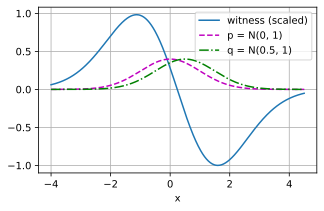

In [5]:
g = lambda s: (rbf(s[:, None], x_p[None, :]).mean(axis=1)    # the unscaled
               - rbf(s[:, None], y_shift[None, :]).mean(axis=1))  # witness
grid = np.linspace(-4.0, 4.5, 400)
witness = g(grid)
print(f'witness changes sign at x = {grid[np.argmax(witness < 0)]:.2f}')
print(f'E_P g - E_Q g = {g(x_p).mean() - g(y_shift).mean():.4f}')
d2l.plot(grid, [witness / np.abs(witness).max(), norm.pdf(grid),
                norm.pdf(grid, loc=0.5)], 'x', '',
         legend=['witness (scaled)', 'p = N(0, 1)', 'q = N(0.5, 1)'],
         figsize=(5, 3))

The witness is positive where $P$ has more mass and negative where $Q$ has
more. It changes sign near $x = 0.25$; with $1{,}000$ points per sample the
crossing moves by a tenth or two from draw to draw. The printed gap agrees with
the last line of the previous output, the unbiased estimate for the same two
samples, to about $0.001$, and the difference is the self-pairs.

The ends of the plot say more than the crossing. A model that lowers the gap
moves each of its samples uphill on the test function, so the slope of the test
function at a sample is the push which that sample receives. The witness is
steep between the two bell curves, and a few length scales away it levels off
toward zero. A model sample out there is told nothing. This is the
$\textrm{MMD}^2$ column of the opening table, seen from one sample.

MMD with a fixed kernel therefore serves twice: as a two-sample test, and as a
loss on which a model is trained without an adversary
[@Li.Swersky.Zemel.2015]. The kernel inception distance by which generated
images are scored is the unbiased estimate of the previous subsection, applied
to image features with a cubic kernel (that section). The length
scale has to be chosen, and a poor choice is costly: at $\ell = 1$ the slope at
$d = 8$ was $7 \times 10^{-5}$ (Exercise
1b tries longer scales).
Common practice sets $\ell$ to the median distance between sample points, or
adds RBF kernels of several length scales, as that section does
when it trains the model of a GAN, its *generator*, on MMD.

## Optimal Transport and the Wasserstein Distance

One column of the opening table never went flat. $W_1$ kept its slope because
it measures distance itself, which the f-divergences ignore and a kernel sees
only nearby: $\delta_{0.01}$ is near $\delta_0$ because its mass need only move
$0.01$. The idea is old. In 1781 Gaspard Monge asked how a heap of soil can be
moved into a pit of the same volume with the least work, and the least work is
a measure of how far the heap is from the pit.

### Transport Plans

Take two distributions on the points $0, 1, \ldots, 5$ of the line, with $P$
mostly on the left and $Q$ mostly on the right, as in the top left panel of
the figure. To turn $P$ into $Q$ we must say how much
mass travels from each source $x$ to each destination $y$. Such a *transport
plan* is a joint distribution $\gamma$ of pairs $(x, y)$ whose marginals are
$P$ and $Q$: what leaves each $x$ is what $P$ has there, and what arrives at
each $y$ is what $Q$ needs. A plan is also called a *coupling* of $P$ and $Q$.
The **Wasserstein-1 distance**, also called the earth mover's distance, is the
least total of mass times distance over all plans. Writing $\Pi(P, Q)$ for the
set of plans, for $P$ and $Q$ on $\mathbb{R}^n$ with finite first moments,

$$
W_1(P, Q) = \inf_{\gamma \in \Pi(P, Q)} \mathbb{E}_{(x, y) \sim \gamma}\big[ \|x - y\| \big].
$$

The $1$ in the name is the power of the distance; the second power comes later.
Between the point masses $\delta_0$ and $\delta_d$ the only plan moves all mass
from $0$ to $d$, so $W_1(\delta_0, \delta_d) = |d|$, with gradient $\pm 1$ for
$d \neq 0$. For the two Gaussians of the opening, shifting every point by $d$
is a plan of cost $d$, and none is cheaper, because
$\mathbb{E}_\gamma|x - y| \geq |\mathbb{E}_\gamma[x - y]| = d$ for every plan.
In both cases $W_1$ is the distance itself, the training signal that the
f-divergences lack.

![Transport on the line. Top left: a plan between two distributions on six points; each ribbon carries mass from a point of $P$ (top) to a point of $Q$ (bottom), and its width is the mass moved. Bottom left: the CDFs of the same $P$ and $Q$; the shaded area between them is $1.7$. Right: for two point masses at separation $d$, the Jensen--Shannon divergence (in nats) stays at $\log 2$ while $W_1$ (in units of $x$) grows with $d$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-it-ot-transport-plan.svg)

### Kantorovich--Rubinstein Duality

As a recipe for computation the definition is discouraging: it optimizes over
joint distributions, which are hard even to parameterize from samples. On
finitely many points it is at least a familiar kind of problem, a linear
program. The unknowns are the entries of the plan, and the cost and the
constraints on the marginals are linear in them. A linear program has a *dual*,
a maximization over multipliers for its constraints
(that section). The dual of transport optimizes over a
single function, and it is the reason $W_1$ matters to deep learning.

**Proposition (Kantorovich--Rubinstein duality).** *For distributions $P$ and
$Q$ on $\mathbb{R}^n$ with finite first moments,*

$$
W_1(P, Q) = \sup_{\|g\|_{\textrm{Lip}} \leq 1}
\big( \mathbb{E}_{x \sim P}[g(x)] - \mathbb{E}_{y \sim Q}[g(y)] \big),
$$

*where the supremum runs over all 1-Lipschitz functions $g$, those with
$|g(x) - g(y)| \leq \|x - y\|$ for all $x, y$.*

An infimum over plans has become a supremum over one function: $W_1$ is the IPM
the equation over test functions of slope at most $1$, the third of
our classes. Such an auditor cannot jump, so it cannot pick out the points of a
sample as an indicator does. It can climb without limit, however, and that is
what the second requirement asked for. For the two Gaussians of the opening
take $g(x) = -x$. Its averages are $0$ under $P$ and $-d$ under $Q$, a gap of
$d$, which is $W_1$, so no auditor of slope one does better. Its slope is the
same at every model sample, however far from the data the sample lies, and
uphill on $g$ is the way to the data.

A network can represent such a function, and the **WGAN**
[@Arjovsky.Chintala.Bottou.2017] trains this dual, with a neural critic in
the role of $g$ that is constrained to be approximately 1-Lipschitz.
that section sets this critic beside the other adversarial
losses, and that section treats the gradient penalties that
enforce the constraint. What an approximately Lipschitz critic reports is, of
course, no longer exactly $W_1$.

### Transport on the Line

We prove the duality only on the line, where the proof also yields a closed
form and transport needs no optimization at all; @Peyre.Cuturi.2019
give the general proof. The idea is to count crossings. At a point $t$, $P$ has
a fraction $F_P(t)$ of its mass at or to the left of $t$ and $Q$ has $F_Q(t)$,
so any plan must carry at least $|F_P(t) - F_Q(t)|$ of mass across $t$. A
parcel moved from $x$ to $y$ crosses every $t$ between them, so its distance
$|x - y|$ is the length of the set of points it crosses, and the total cost is
the mass crossing each $t$, integrated over $t$.

**Proposition ($W_1$ on the line).** *For distributions $P$ and $Q$ on
$\mathbb{R}$ with CDFs $F_P$, $F_Q$ and finite first moments,*

$$
W_1(P, Q) = \int_{-\infty}^{\infty} \lvert F_P(t) - F_Q(t) \rvert \, dt
= \sup_{\|g\|_{\textrm{Lip}} \leq 1}
\big( \mathbb{E}_P[g] - \mathbb{E}_Q[g] \big),
$$

*so Kantorovich--Rubinstein duality holds on the line.*

**Proof.** *Step 1: every plan costs at least the area.* For
$(X, Y) \sim \gamma$,
$|X - Y| = \int \mathbf{1}(t \textrm{ lies between } X \textrm{ and } Y)\, dt$.
The integrand is non-negative, so expectation and integral may be exchanged:

$$
\mathbb{E}_\gamma|X - Y|
= \int \Big( \gamma(X \leq t < Y) + \gamma(Y \leq t < X) \Big)\, dt
\geq \int \big| \gamma(X \leq t < Y) - \gamma(Y \leq t < X) \big|\, dt.
$$

The step that is not routine is the difference inside the last integral. Add
and subtract $\gamma(X \leq t, Y \leq t)$: then
$\gamma(X \leq t < Y) - \gamma(Y \leq t < X) = \gamma(X \leq t) - \gamma(Y \leq t) = F_P(t) - F_Q(t)$,
because the marginals of $\gamma$ are $P$ and $Q$. So every plan costs at least
$\int |F_P - F_Q|$.

*Step 2: one plan costs exactly the area.* Send quantile to quantile: the
lowest tenth of $P$ goes to the lowest tenth of $Q$, and so on upward. In
symbols, let $U$ be uniform on $(0, 1)$ and set $X = F_P^{-1}(U)$,
$Y = F_Q^{-1}(U)$, with the quantile function
$F^{-1}(\lambda) = \inf\{x : F(x) \geq \lambda\}$ for $\lambda \in (0, 1)$,
which satisfies $F^{-1}(\lambda) \leq t$ exactly when $\lambda \leq F(t)$. This
is a plan, because $\Pr(X \leq t) = \Pr(U \leq F_P(t)) = F_P(t)$ and likewise
for $Y$. We call it the *monotone plan*, since $X$ and $Y$ rise together. Then
$\gamma(X \leq t < Y) = \Pr\big(F_Q(t) < U \leq F_P(t)\big)$ and
$\gamma(Y \leq t < X) = \Pr\big(F_P(t) < U \leq F_Q(t)\big)$. At least one of
the two is zero: the monotone plan never carries mass both ways across a point.
The inequality of Step 1 is therefore an equality for this plan, and the least
cost over plans equals the area.

*Step 3: no test function beats any plan.* This is *weak duality*, and it holds
in any dimension. For a 1-Lipschitz $g$ and a plan $\gamma$,
$g(x) - g(y) \leq \|x - y\|$ at every pair, and taking the expectation under
$\gamma$ gives
$\mathbb{E}_P[g] - \mathbb{E}_Q[g] \leq \mathbb{E}_\gamma\|x - y\|$ (compare
the weak duality of that section).

*Step 4: one test function attains the area.* It suffices to consider
$g(x) = g(0) + \int_0^x g'(t)\, dt$ with $|g'| \leq 1$: every such $g$ is
1-Lipschitz, and Step 3 already bounds all the others. The constant $g(0)$
cancels in $\mathbb{E}_P[g] - \mathbb{E}_Q[g]$. Writing
$\int_0^X g'(t)\,dt = \int_0^{\infty} g'(t)\, \mathbf{1}(X > t)\, dt - \int_{-\infty}^0 g'(t)\, \mathbf{1}(X \leq t)\, dt$
and swapping expectation and integral (Fubini's theorem from
that section, which the finite first moments justify),

$$
\mathbb{E}_P[g] - \mathbb{E}_Q[g] = \int_{-\infty}^{\infty} g'(t)\, \big( F_Q(t) - F_P(t) \big)\, dt.
$$

The choice $g'(t) = \textrm{sign}\big(F_Q(t) - F_P(t)\big)$ makes the right
side equal to the area. Together, the supremum over test functions is at least
the area (Step 4) and at most the least cost over plans (Step 3), which equals
the area (Steps 1 and 2). $\blacksquare$

On the line, then, $W_1$ is the area between the two CDFs, and for two samples
of equal size it is the mean absolute difference of the sorted values (Exercise
4a). It is rather
surprising that a linear program should collapse this far. We watch it happen
once, on the six points of the figure. Between
neighboring points the two CDFs differ by $0.25$, $0.35$, $0.5$, $0.35$ and
$0.25$, which sum to $1.7$, the shaded area in the figure. The cell computes
$W_1$ three times. It adds up the five gaps. It solves the linear program over
plans, where a plan is a $6 \times 6$ matrix with row sums $p$ and column sums
$q$. And it builds the monotone plan of Step 2, in which each route carries the
overlap of two quantile intervals, and adds up its cost. The last line of the
output compares the plan that the linear program returned with the monotone
plan.

In [6]:
atoms = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0])
p_w = np.array([0.30, 0.20, 0.25, 0.10, 0.10, 0.05])
q_w = np.array([0.05, 0.10, 0.10, 0.25, 0.20, 0.30])

F_p, F_q = np.cumsum(p_w), np.cumsum(q_w)
w1_cdf = np.sum(np.abs(F_p - F_q)[:-1] * np.diff(atoms))

C = np.abs(atoms[:, None] - atoms[None, :])      # cost matrix |x_i - y_j|
n_atoms = len(atoms)
A_eq = np.zeros((2 * n_atoms, n_atoms * n_atoms))
for i in range(n_atoms):
    A_eq[i, i * n_atoms:(i + 1) * n_atoms] = 1   # row sums    = p
    A_eq[n_atoms + i, i::n_atoms] = 1            # column sums = q
res = optimize.linprog(C.ravel(), A_eq=A_eq,
                       b_eq=np.concatenate([p_w, q_w]), method='highs')
plan_lp = res.x.reshape(n_atoms, n_atoms)
# Monotone plan (Step 2): source i holds the quantiles (F_p[i-1], F_p[i]],
# destination j holds (F_q[j-1], F_q[j]]; route i -> j carries their overlap
lo_p, lo_q = F_p - p_w, F_q - q_w
mono = np.clip(np.minimum(F_p[:, None], F_q[None, :])
               - np.maximum(lo_p[:, None], lo_q[None, :]), 0, None)
print(f'W1 from the CDF gaps     : {w1_cdf:.4f}')
print(f'W1 from the LP           : {res.fun:.4f}')
print(f'cost of the monotone plan: {np.sum(mono * C):.4f}')
print(f'LP plan = monotone plan  : {np.allclose(plan_lp, mono)}, '
      f'mass the LP plan moves leftward: {np.tril(plan_lp, -1).sum():.2f}')

W1 from the CDF gaps     : 1.7000
W1 from the LP           : 1.7000
cost of the monotone plan: 1.7000
LP plan = monotone plan  : False, mass the LP plan moves leftward: 0.00


All three computations give $W_1 = 1.7$: one sum over five gaps replaces a
$36$-variable linear program. The last line is the unexpected one. The linear
program did not return the monotone plan. It returned another plan of the same
cost, which also moves no mass to the left.

The optimal plan is not unique here, then, and the reason is simple.
$F_P \geq F_Q$ at every point, so no mass has to move left, and for a plan
that moves mass only rightward $|x - y| = y - x$. Its cost is then the
difference of the two means, $3.35 - 1.65 = 1.7$, whatever else the plan does.
The monotone plan, the one drawn in the figure, is one of many optimal plans.

Two tools that we meet elsewhere measure transport with the square of the
distance: the Fréchet inception distance, the other score for generated images
(that section), and the minibatch pairing of flow matching, which
matches noise to data by the plan of least squared distance
(that section). The **Wasserstein-2 distance**
squares the distance before averaging and takes the square root afterwards,
$W_2(P, Q) = \big(\inf_{\gamma} \mathbb{E}_\gamma \|x - y\|^2\big)^{1/2}$.
Under the squared cost two ribbons that cross always cost more than the same
two uncrossed, so on the line the monotone plan is the only optimum (Exercise
4d). Between two Gaussians
on the line with means $\mu_1, \mu_2$ and standard deviations
$\sigma_1, \sigma_2$ it gives
$W_2^2 = (\mu_1 - \mu_2)^2 + (\sigma_1 - \sigma_2)^2$ (Exercise
6a). The Fréchet inception
distance is the same expression for Gaussians fitted to image features, with
covariance matrices in place of the variances.

### Entropic Regularization and Sinkhorn Iterations

This subsection can be skipped on a first reading. Off the line there is in
general no CDF formula, and the linear program has $N^2$ variables for $N$
points on each side. The standard remedy is **entropic regularization**
[@Cuturi.2013]: we add the term
$\varepsilon \sum_{ij} \gamma_{ij} (\log \gamma_{ij} - 1)$ to the transport
cost $\sum_{ij} \gamma_{ij} C_{ij}$, for a cost matrix $\mathbf{C}$ and a
regularizer $\varepsilon > 0$. On plans, $\sum_{ij}\gamma_{ij} = 1$, so the
added term is $-\varepsilon$ times the entropy of $\gamma$ plus a constant; it
penalizes plans that concentrate on few routes. With it, transport became
usable as a loss in deep learning, and generative models are trained on the
regularized cost directly [@Genevay.Peyre.Cuturi.2018].

The regularized problem can be solved almost in closed form. Its Lagrangian, as
in that section, adds a multiplier $\xi_i$ for each
row-sum constraint $\sum_j \gamma_{ij} = p_i$ and $\zeta_j$ for each column-sum
constraint $\sum_i \gamma_{ij} = q_j$. Setting its derivative in $\gamma_{ij}$
to zero gives $C_{ij} + \varepsilon \log \gamma_{ij} - \xi_i - \zeta_j = 0$, so
$\gamma_{ij} = e^{-(C_{ij} - \xi_i - \zeta_j)/\varepsilon}$: a route carries
mass according to how far its cost exceeds $\xi_i + \zeta_j$, in units of
$\varepsilon$. In matrix form,

$$
\boldsymbol{\gamma}_\varepsilon = \textrm{diag}(\mathbf{a})\, \mathbf{K}\, \textrm{diag}(\mathbf{b}),
\qquad \mathbf{K} = e^{-\mathbf{C}/\varepsilon} \textrm{ (entrywise)},
$$

with positive scalings $\mathbf{a} = e^{\boldsymbol{\xi}/\varepsilon}$ and
$\mathbf{b} = e^{\boldsymbol{\zeta}/\varepsilon}$. The regularized plan is the
*Gibbs kernel* $\mathbf{K}$ (a matrix of positive weights, unrelated to the
kernels of MMD), rescaled row by row and column by column. Only the scalings
are unknown, and each half of the constraints determines one of them. With
$\mathbf{b}$ fixed, $\mathbf{a} = \mathbf{p} / (\mathbf{K}\mathbf{b})$
(entrywise) makes the row sums equal to $\mathbf{p}$. With $\mathbf{a}$ fixed,
$\mathbf{b} = \mathbf{q} / (\mathbf{K}^\top \mathbf{a})$ makes the column sums
equal to $\mathbf{q}$.

The **Sinkhorn iterations** alternate these two updates, first $\mathbf{b}$
and then $\mathbf{a}$. After the second update the row sums are right, and we
stop once the column sums agree with $\mathbf{q}$ to within $10^{-9}$ as well.
Each iteration costs two matrix-vector products, so the iterations run well on
a GPU and can be differentiated through. We report the *entropic cost*, the
transport cost
$\sum_{ij} (\gamma_\varepsilon)_{ij} C_{ij}$ of the regularized plan without
the entropy term. As $\varepsilon \to 0$ it approaches the unregularized
optimum, but the iterations converge ever more slowly
[@Peyre.Cuturi.2019], and the entries of $\mathbf{K}$ underflow, so
practical code iterates on $\log \mathbf{a}$ and $\log \mathbf{b}$ (Exercise
7b).

To see how small $\varepsilon$ must be, and what a small $\varepsilon$ takes,
we use the squared cost $C_{ij} = (x_i - x_j)^2$ on the six-point example, for
which the monotone plan of the figure is the only
optimum and its ten routes cost $W_2^2 = 3.5$. The cell checks this value with
the linear program and runs Sinkhorn at three values of $\varepsilon$. For each
it prints the number of iterations, the entropic cost, and the number of routes
that carry more than $10^{-3}$ of mass.

squared cost, LP optimum : 3.50000
epsilon = 2.0:     47 iterations, entropic cost = 4.06489, routes above 1e-3 = 25
epsilon = 0.5:    186 iterations, entropic cost = 3.56963, routes above 1e-3 = 14


epsilon = 0.1: 154325 iterations, entropic cost = 3.50002, routes above 1e-3 = 10


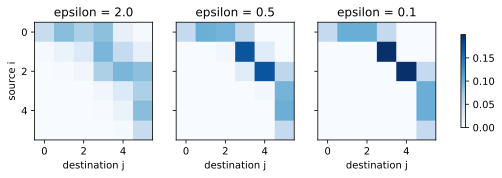

In [7]:
def sinkhorn(p, q, C, eps, tol=1e-9, max_iters=10 ** 6):
    """Entropic OT by Sinkhorn iterations, stopped once the column sums are
    within tol of q (L1); returns the plan, its cost and the iterations."""
    K = np.exp(-C / eps)                         # the Gibbs kernel
    a = np.ones_like(p)
    for it in range(1, max_iters + 1):
        b = q / (K.T @ a)                        # match the column sums
        a = p / (K @ b)                          # match the row sums ...
        if np.abs(b * (K.T @ a) - q).sum() < tol:  # ... columns still right?
            break
    plan = a[:, None] * K * b[None, :]
    return plan, np.sum(plan * C), it

C2 = (atoms[:, None] - atoms[None, :]) ** 2      # squared cost (x_i - y_j)^2
res2 = optimize.linprog(C2.ravel(), A_eq=A_eq,
                        b_eq=np.concatenate([p_w, q_w]), method='highs')
print(f'squared cost, LP optimum : {res2.fun:.5f}')
plans, eps_values = [], (2.0, 0.5, 0.1)
for eps in eps_values:
    plan, cost, iters = sinkhorn(p_w, q_w, C2, eps)
    plans.append(plan)
    print(f'epsilon = {eps}: {iters:6d} iterations, entropic cost = '
          f'{cost:.5f}, routes above 1e-3 = {(plan > 1e-3).sum()}')
d2l.show_heatmaps(d2l.tensor(np.stack(plans)[None]), 'destination j',
                  'source i', titles=[f'epsilon = {e}' for e in eps_values],
                  figsize=(9, 2.8), cmap='Blues')

The linear program agrees on $3.5$. At $\varepsilon = 2$ the plan spreads each
source's mass over several destinations ($25$ of the $36$ routes carry more
than $10^{-3}$), and its cost, $4.06$, is well above the optimum. At
$\varepsilon = 0.5$ the plan has $14$ routes and costs $3.57$. At
$\varepsilon = 0.1$ only the ten routes of the monotone plan remain, and the
cost, $3.50002$, lies above the optimum by $2 \times 10^{-5}$. In the heat
maps a broad band sharpens into a staircase. The yardstick for $\varepsilon$
is the difference in cost between competing routes, which is of order $1$ on
this grid, and a tenth of it was small enough.

The iteration counts show what this accuracy takes. About $50$ iterations were
enough at $\varepsilon = 2$ and about $190$ at $\varepsilon = 0.5$, but
$\varepsilon = 0.1$ needed some $150{,}000$. Between the last two runs
$\varepsilon$ fell fivefold and the work grew $800$ times. Sinkhorn iterations
are fast only as long as the plan may stay blurred (Exercise
8b measures the
growth).

## Fixed Kernels and Trained Critics

MMD and $W_1$ divide the two requirements between them. The class behind a
fixed kernel is small. MMD costs three averages, and the error of its estimate
from $N$ points is of order $N^{-1/2}$ in any dimension
[@Gretton.Borgwardt.Rasch.ea.2012], but it sees only a few length scales.
The functions of slope at most one see at every distance, which is what a model
far from its data needs. They cannot jump, and yet in many dimensions they are
still a very large class: between two samples in dimension $n > 2$ the error of
$W_1$ is of order $N^{-1/n}$ [@Weed.Bach.2019]. In $100$ dimensions,
halving that error takes $2^{100}$ times the data. Nobody estimates $W_1$ that
way. A critic network searches a far smaller class than all functions of slope
one, and Sinkhorn iterations serve where the problem is small.

Kernel and critic alike begin by drawing samples from the model. For some
models that is the expensive step, and that section asks what can
be compared without it.

## Summary

A little overlap does not bring the gradient back: for two unit Gaussians eight
standard deviations apart, the Jensen--Shannon divergence and total variation
have slopes near $10^{-4}$. An integral probability metric compares instead how
$P$ and $Q$ average a class of test functions, and the class decides both
whether samples can estimate the gap and how far the comparison sees. Functions
that are linear in fixed features give MMD, the distance between mean features:
it is three kernel averages, which samples estimate with no critic, and it is
blind beyond a few length scales. Functions of slope at most one give $W_1$,
the least mass times distance that turns one distribution into the other, which
keeps a slope of one at every separation and is what the critic of a
Wasserstein GAN estimates. On the line $W_1$ is the area between the CDFs;
elsewhere it needs a trained critic or, for small problems, Sinkhorn iterations
on an entropically regularized plan.

## Exercises

1. [code] **MMD in closed form.** Use the Gaussian integral
   the equation for the RBF kernel with length scale
   $\ell$, with $P = \mathcal{N}(0, 1)$ and $Q = \mathcal{N}(d, 1)$.
    1. Show that
       $\textrm{MMD}^2 = \frac{2\ell}{\sqrt{\ell^2 + 2}}
       \big(1 - e^{-d^2/(2(\ell^2 + 2))}\big)$, and check that $\ell = 1$
       gives the $\textrm{MMD}^2$ column of the opening table. Which length
       scale maximizes $\textrm{MMD}^2$ for small shifts $d$? What happens
       as $\ell \to 0$ and as $\ell \to \infty$?
    1. Evaluate the slope in $d$ at $d = 8$ for $\ell = 1$, $4$ and $16$.
       What do the three values say about the length scale for a model that
       starts far from its data?

1. [code] **Sampling error of the MMD estimate.** At $\ell = 1$ and
   $d = 0.5$ the closed form $\tfrac{2}{\sqrt{3}}\big(1 - e^{-d^2/6}\big)$
   gives $0.047$.
    1. Recompute `mmd2_unbiased` with the RBF kernel on $200$ fresh pairs of
       samples drawn like `x_p` and `y_shift`, with `n = 250` and with
       `n = 1000`, and compare the mean and the standard deviation of the
       estimates with the closed form. How does the standard deviation scale
       with the sample size? Is the value that your run of the MMD
       experiment printed within the spread?
    1. Repeat for pairs drawn like `x_p` and `y_same`. The standard
       deviation now scales differently. How, and why does this help a test
       of $P = Q$?

1. **Rescaling and the data-processing inequality.** An f-divergence is
   $D_f(P\|Q) = \mathbb{E}_{x \sim Q}[f(p(x)/q(x))]$ for a convex $f$ with
   $f(1) = 0$, and it satisfies the data-processing inequality
   $D_f(P\kappa \,\|\, Q\kappa) \leq D_f(P\|Q)$ for every channel $\kappa$,
   that is, for every deterministic or random map applied to both
   distributions (that section). Apply the map
   $x \mapsto 2x$ to both $P$ and $Q$.
    1. Show from the definition that no f-divergence changes under an
       invertible map, and that $W_1$ doubles.
    1. Show that the RBF $\textrm{MMD}^2$ at $\ell = 1$ falls from $0.047$ to
       $0.036$ for $\mathcal{N}(0, 1)$ against $\mathcal{N}(0.5, 1)$, but
       rises from $0.235$ to $0.787$ for $\delta_0$ against $\delta_{0.5}$.
       Why does the data-processing inequality say nothing about MMD and
       $W_1$?

1. [code] **One-dimensional transport.** ● On the real line, $W_1$ is the
   area between the CDFs the equation.
    1. For two empirical distributions on samples $x_1, \ldots, x_N$ and
       $y_1, \ldots, y_N$ of equal size, use the monotone plan of the proof
       to show that $W_1 = \tfrac{1}{N} \sum_i |x_{(i)} - y_{(i)}|$, the mean
       absolute difference of the sorted values. Check this against the
       linear program of the six-point example on two random samples of
       size $7$.
    1. Compute the sorted-sample $W_1$ between `x_p` and `y_shift` and
       between `x_p` and `y_same` of the MMD experiment. Then average it
       over $20$ pairs of independent samples of size $N$ from
       $\mathcal{N}(0, 1)$, for $N \in \{10^2, 10^3, 10^4\}$, and find the
       rate at which it decreases. The estimate is never negative. Why does
       this rule out unbiasedness when $P = Q$?
    1. Change `q_w` to $(0.40, 0.05, 0.05, 0.10, 0.10, 0.30)$, so that the
       two CDFs cross, and rerun the cell that computes $W_1$. Build the test
       function $g$ with $g(0) = 0$ and slope
       $\textrm{sign}\big(F_Q(t) - F_P(t)\big)$ between neighboring atoms, as
       in Step 4 of the proof, and check that
       $\mathbb{E}_P[g] - \mathbb{E}_Q[g]$ equals the LP value. For every
       route $(i, j)$ that carries mass in the LP solution `plan_lp`, compare
       $g(x_i) - g(x_j)$ with $|x_i - x_j|$. Why must the two agree on every
       such route for any optimal plan and any optimal test function?
    1. *Uniqueness under the squared cost.* Suppose a plan moves mass from
       $x$ to $y'$ and from $x'$ to $y$, with $x < x'$ and $y < y'$, so that
       the two ribbons cross. Show that under the squared cost, sending the
       same mass from $x$ to $y$ and from $x'$ to $y'$ saves
       $2(x' - x)(y' - y)$ per unit of mass, and deduce that the monotone
       plan is the only optimal one. What does the same exchange save under
       the cost $|x - y|$ when all four moves go rightward? Find two ribbons
       that cross in `plan_lp`, the plan that the linear program returned for
       the six-point example, and check your answer on them.

1. **Optimal critics on the line.** Step 4 of the proof of
   the equation shows that a test function with slope
   $g'(t) = \textrm{sign}\big(F_Q(t) - F_P(t)\big)$ attains $W_1$.
    1. For $P = \mathcal{N}(0, 1)$ and $Q = \mathcal{N}(d, 1)$ with $d > 0$,
       show that $F_P > F_Q$ everywhere, so that Step 4 returns
       $g(x) = -x$, the critic that the text found by inspection.
    1. For $P = \mathcal{N}(0, 1)$ and $Q = \mathcal{N}(0, 4)$, show that
       the two CDFs cross only at $0$, that $g(x) = -|x|$ is optimal, and
       that $W_1 = \sqrt{2/\pi} \approx 0.80$. (For
       $X \sim \mathcal{N}(0, \sigma^2)$, $\mathbb{E}|X| = \sigma\sqrt{2/\pi}$.)
       The linear kernel reported $0$ on this pair. Which way does the
       critic move the samples of $Q$?
    1. Let $P = \tfrac12 \delta_0 + \tfrac12 \delta_3$ and
       $Q = \tfrac12 \delta_1 + \tfrac12 \delta_3$. Find $W_1(P, Q)$ and
       describe every optimal critic of the form used in Step 4. Then show
       in general that such a critic is optimal if and only if
       $g'(t) = \textrm{sign}\big(F_Q(t) - F_P(t)\big)$ at almost every $t$
       with $F_P(t) \neq F_Q(t)$, the points that mass has to cross, while
       its slope elsewhere is free.
    1. A WGAN critic is often trained with a penalty on
       $(|g'(x)| - 1)^2$ at points $x$ between the data and the generated
       samples [@Gulrajani.Ahmed.Arjovsky.ea.2017]. Explain this choice
       by (c). Which critics are optimal when $P = Q$, and which of them does
       the penalty prefer? that section shows what follows
       for training.

1. [code] **$W_2$ between Gaussians and the Fréchet distance.** On the
   line the monotone plan $X = F_P^{-1}(U)$, $Y = F_Q^{-1}(U)$ is optimal
   for the squared cost.
    1. Show that for $P = \mathcal{N}(\mu_1, \sigma_1^2)$ and
       $Q = \mathcal{N}(\mu_2, \sigma_2^2)$ the monotone plan is
       $Y = \mu_2 + (\sigma_2/\sigma_1)(X - \mu_1)$, and deduce that
       $W_2^2(P, Q) = (\mu_1 - \mu_2)^2 + (\sigma_1 - \sigma_2)^2$. With the
       same plan, recover $W_1 = |\mu_1 - \mu_2|$ for equal variances, the
       $W_1$ column of the opening table.
    1. Let both standard deviations be $\sigma$ and the means $d$ apart. Then
       $W_2^2 = d^2$ for every $\sigma$, while the KL divergence between the
       two Gaussians is $d^2/(2\sigma^2)$. What do the two report as
       $\sigma \to 0$, when the Gaussians become the point masses of
       the table?
    1. In $\mathbb{R}^n$ the squared $W_2$ between
       $\mathcal{N}(\boldsymbol{\mu}_1, \boldsymbol{\Sigma}_1)$ and
       $\mathcal{N}(\boldsymbol{\mu}_2, \boldsymbol{\Sigma}_2)$ is the
       squared *Fréchet distance*
       $\|\boldsymbol{\mu}_1 - \boldsymbol{\mu}_2\|^2 + \textrm{tr}\big(\boldsymbol{\Sigma}_1 + \boldsymbol{\Sigma}_2 - 2\,(\boldsymbol{\Sigma}_1^{1/2} \boldsymbol{\Sigma}_2 \boldsymbol{\Sigma}_1^{1/2})^{1/2}\big)$
       [@Dowson.Landau.1982]. Check that it reduces to (a) for $n = 1$
       and, for diagonal covariance matrices, to the sum of (a) over the
       coordinates. Prove the diagonal case directly: the squared cost is a
       sum over coordinates, so no plan costs less than the sum of the
       coordinatewise optima, and the monotone plans of the coordinates
       together attain it.
    1. The Fréchet inception distance fits a Gaussian to each of two feature
       distributions and reports the squared Fréchet distance between the
       fits. Let $P$ be the mixture
       $0.7\,\mathcal{N}(-2, 0.6^2) + 0.3\,\mathcal{N}(2, 0.6^2)$ and
       $Q = \mathcal{N}(-0.8, 3.72)$, which has the same mean and variance.
       What is the Fréchet distance between the two fits? Estimate
       $W_2^2(P, Q)$ from $10^5$ sorted draws of each (you should find about
       $0.63$). What does a Fréchet distance of zero certify, and what does
       it not?

1. [code] **Entropic transport and Sinkhorn divergences.** ●● Regularize the
   transport LP of the six-point example by the divergence from the
   independent plan,

   $$
   \textrm{OT}_\varepsilon(P, Q) = \min_{\gamma}\, \sum_{i, j} \gamma_{ij} C_{ij}
   + \varepsilon\, D_{\textrm{KL}}\big(\gamma \,\|\, p\, q^\top\big),
   $$

   where $\gamma$ ranges over the plans with row sums $p$ and column sums
   $q$.
    1. Show that
       $D_{\textrm{KL}}(\gamma \,\|\, p\, q^\top) = -H(\gamma) + H(P) + H(Q)$
       for every such plan, where $H$ denotes the entropy, so that `sinkhorn`
       returns the minimizer. Show that
       $\textrm{OT}_\varepsilon(P, Q) \to \sum_{i, j} p_i q_j C_{ij}$
       as $\varepsilon \to \infty$, and that
       $\textrm{OT}_\varepsilon(P, P) > 0$ for every $\varepsilon > 0$
       unless $P$ is a point mass. With $C_{ij} = |x_i - x_j|$, show that
       the distributions $P$ on the atoms that minimize the limit
       $\sum_{i, j} p_i q_j C_{ij}$ put all their mass on medians of $Q$,
       for `q_w` the atoms $3$ and $4$. What would a model trained on
       $\textrm{OT}_\varepsilon$ with a large $\varepsilon$ learn?
    1. The Sinkhorn divergence
       $S_\varepsilon(P, Q) = \textrm{OT}_\varepsilon(P, Q)
       - \tfrac{1}{2} \textrm{OT}_\varepsilon(P, P)
       - \tfrac{1}{2} \textrm{OT}_\varepsilon(Q, Q)$ removes this bias
       [@Genevay.Peyre.Cuturi.2018; @Feydy.Sejourne.Vialard.ea.2019].
       Compute $S_\varepsilon(P, Q)$ for `p_w` and `q_w` with the absolute
       cost `C` at $\varepsilon \in \{10^{-3}, 10^{-2}, \ldots, 10^3\}$. At
       $\varepsilon = 10^{-3}$ the entries of $\mathbf{K}$ underflow, so
       carry out the Sinkhorn updates on $\log \mathbf{a}$ and
       $\log \mathbf{b}$ there, with `scipy.special.logsumexp`. Check that
       $S_\varepsilon$ approaches $W_1$ as $\varepsilon \to 0$ and
       $\tfrac{1}{2} \mathcal{E}(P, Q)$ as $\varepsilon \to \infty$, where
       $\mathcal{E}(P, Q) = 2\mathbb{E}|X - Y| - \mathbb{E}|X - X'| - \mathbb{E}|Y - Y'|$
       is the energy distance [@Szekely.Rizzo.2013], the expression
       the equation with $-|x - y|$ in place of the kernel. Derive
       the second limit from (a).

1. [code] **Sinkhorn iterations at small $\varepsilon$.** ● Use `sinkhorn`,
   `p_w` and `q_w` of the six-point example.
    1. *Stopping early.* Call `sinkhorn` with the squared cost `C2` at
       $\varepsilon = 0.1$ and `max_iters=5000`, so that the loop ends before
       the column sums have settled. The cost that it returns is below the
       optimum $3.5$. Print the column sums of the returned matrix minus
       `q_w`. Which destinations receive too little, and why does that lower
       the cost? Why can no matrix with row sums `p_w` and column sums `q_w`
       cost less than $3.5$?
    1. *The number of iterations.* Count the iterations that `sinkhorn`
       needs with `C2` at
       $\varepsilon \in \{2, 1, 0.5, 0.3, 0.2, 0.15, 0.1\}$, and plot the
       logarithm of the count against $1/\varepsilon$. What kind of growth do
       the points at small $\varepsilon$ show, and what count does it predict
       for $\varepsilon = 0.05$?
    1. *Ties.* Under the absolute cost `C` every plan that moves mass only
       rightward is optimal for `p_w` and `q_w`. Run `sinkhorn` with `C` at
       $\varepsilon = 0.1$ and $0.02$. How many routes carry mass? Show that
       the limit plan has the form $\gamma_{ij} = a_i b_j$ for $j \geq i$
       and $0$ otherwise. On plans the regularizer is $-\varepsilon$ times
       the entropy plus a constant. Use this to explain why the limit is the
       plan of largest entropy among the optimal plans.

<!-- Discussions: forum topic to be created at deploy -->